In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import pickle


gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")
atom_indices_protein = gleap_target.topology.select("resid 23 to 126")
atom_indices_rna     = gleap_target.topology.select("resid  0 to  22")
atom_indices_rna_docking_surface = gleap_target.topology.select("resid 7 to 16")
atom_index_protein_min = min(atom_indices_protein)

cmd_interactions = {}
pacs_interactions = {}
pacs_com_distances = {}
# for key in ["hbond", "charge-attraction", "pi-stacking", "cation-pi", "vdw"]:
for key in ["hbond", "charge-attraction", "cation-pi", "pi-stacking"]:
    cmd_interactions[key] = np.zeros((5, len(atom_indices_protein), len(atom_indices_rna), 1800), dtype=np.float32)
    nonzero_indices, nonzero_values = pickle.load(open(f"./pickle-cache/interactions_{key}/cmd_interactions.pickle", "rb"))
    cmd_interactions[key][nonzero_indices] = nonzero_values

    pacs_interactions[key] = np.zeros((50, len(atom_indices_protein), len(atom_indices_rna), 120), dtype=np.float32)
    for trial in range(50):
        nonzero_indices, nonzero_values = pickle.load(open(f"./pickle-cache/interactions_{key}/pacs_interactions_{trial}.pickle", "rb"))
        pacs_interactions[key][trial][nonzero_indices] = nonzero_values
        pacs_com_distances_bincount = pickle.load(open(f"./pickle-cache/interactions_{key}/pacs_com_distances_bincount_{trial}.pickle", "rb"))
        pacs_interactions[key][trial] /= pacs_com_distances_bincount[np.newaxis, np.newaxis, :]

/tmp/ipykernel_2250815/4004483477.py:27: RuntimeWarning: invalid value encountered in divide
  pacs_interactions[key][trial] /= pacs_com_distances_bincount[np.newaxis, np.newaxis, :]


In [2]:
xtcs = []
for trial_cmd in range(5):
    xtcs.append(md.load(f"../20250801_FUS-RRM/6_cmd-{trial_cmd+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001::10])

In [3]:
snapshots = []
atom_pairs = [
    [gleap_target.topology.select("resid 11 and name H61")[0], gleap_target.topology.select("resid 72 and name   O")[0]],
    [gleap_target.topology.select("resid 12 and name  H3")[0], gleap_target.topology.select("resid 74 and name OG1")[0]],
    [gleap_target.topology.select("resid 12 and name  O2")[0], gleap_target.topology.select("resid 74 and name   H")[0]],
]
print(atom_pairs)

for trial_cmd in range(5):
    for timestep in range(1800):
        for index_rna, index_protein in atom_pairs:
            if cmd_interactions["hbond"][trial_cmd, index_protein-atom_index_protein_min, index_rna, timestep] == 0:
                break
        else:
            snapshots.append(xtcs[trial_cmd][timestep])
print(len(snapshots))
md.join(snapshots).save_xtc("interactions_figure/A12U13.xtc")

[[373, 1482], [407, 1514], [409, 1505]]
1208


In [4]:
snapshots = []
atom_pairs = [
    [gleap_target.topology.select("resid 13 and name  O2")[0], gleap_target.topology.select("resid 118 and name   H")[0]],
    # [gleap_target.topology.select("resid 13 and name \"O2'\"")[0], gleap_target.topology.select("resid 118 and name HG1")[0]],
    # [gleap_target.topology.select("resid 13 and name \"O2'\"")[0], gleap_target.topology.select("resid 118 and name   O")[0]],
]
print(atom_pairs)

for trial_cmd in range(5):
    for timestep in range(1800):
        for index_rna, index_protein in atom_pairs:
            if cmd_interactions["hbond"][trial_cmd, index_protein-atom_index_protein_min, index_rna, timestep] == 0:
                break
        else:
            snapshots.append(xtcs[trial_cmd][timestep])
print(len(snapshots))
md.join(snapshots).save_xtc("interactions_figure/U14.xtc")

[[439, 2157]]
8890


In [5]:
snapshots = []
atom_pairs = [
    [gleap_target.topology.select("resid 14 and name OP2")[0], gleap_target.topology.select("resid 120 and name   H")[0]],
    [gleap_target.topology.select("resid 14 and name OP2")[0], gleap_target.topology.select("resid 121 and name   H")[0]],
    [gleap_target.topology.select("resid 14 and name H42")[0], gleap_target.topology.select("resid 117 and name   O")[0]],
    [gleap_target.topology.select("resid 14 and name  O2")[0], gleap_target.topology.select("resid  34 and name HG1")[0]],
]
print(atom_pairs)

for trial_cmd in range(5):
    for timestep in range(1800):
        for index_rna, index_protein in atom_pairs:
            if cmd_interactions["hbond"][trial_cmd, index_protein-atom_index_protein_min, index_rna, timestep] == 0:
                break
        else:
            snapshots.append(xtcs[trial_cmd][timestep])
print(len(snapshots))
md.join(snapshots).save_xtc("interactions_figure/C15.xtc")

[[449, 2195], [449, 2219], [467, 2155], [470, 874]]
148


In [6]:
snapshots = []
atom_pairs = [
    [gleap_target.topology.select("resid 11 and name H61")[0], gleap_target.topology.select("resid 72 and name   O")[0]],
    [gleap_target.topology.select("resid 12 and name  H3")[0], gleap_target.topology.select("resid 74 and name OG1")[0]],
    [gleap_target.topology.select("resid 12 and name  O2")[0], gleap_target.topology.select("resid 74 and name   H")[0]],
]
for trial_cmd in range(5):
    for timestep in range(1800):
        for index_rna, index_protein in atom_pairs:
            if cmd_interactions["hbond"][trial_cmd, index_protein-atom_index_protein_min, index_rna, timestep] == 0:
                break
        else:
            snapshots.append(xtcs[trial_cmd][timestep])
md.join(snapshots).save_xtc("interactions_figure/A12U13.xtc")

hbond A12-H61-Leu324(O) 0.4470377 0.0
hbond U13-H3-Thr326(OG1) 0.5834829 0.078841515
hbond U13-O2-Thr326(H) 0.5996409 0.08045052
hbond U14-O2-Thr370(H) 0.994614 0.9863234
hbond U14-O2'-Thr370(HG1) 0.55655295 0.5108608
hbond U14-HO2'-Thr370(O) 0.72890484 0.67497987
hbond C15-OP2-Arg372(H) 0.6947935 0.59372485
hbond C15-OP2-Ala373(H) 0.38779175 0.2453741
hbond C15-H42-Ala369(O) 0.38779175 0.3974256
hbond C15-O2-Thr286(HG1) 0.31597847 0.2461786

charge-attraction U14-OP2-Lys334(NZ) 0.06642729 0.23411103

cation-pi U13-N1-Arg328(NH1) 0.5745063 0.3829445
cation-pi C15-N1-Arg371(NH1) 0.54578096 0.5703942

pi-stacking U14-N1-Phe288(CG) 1.0 0.9975865



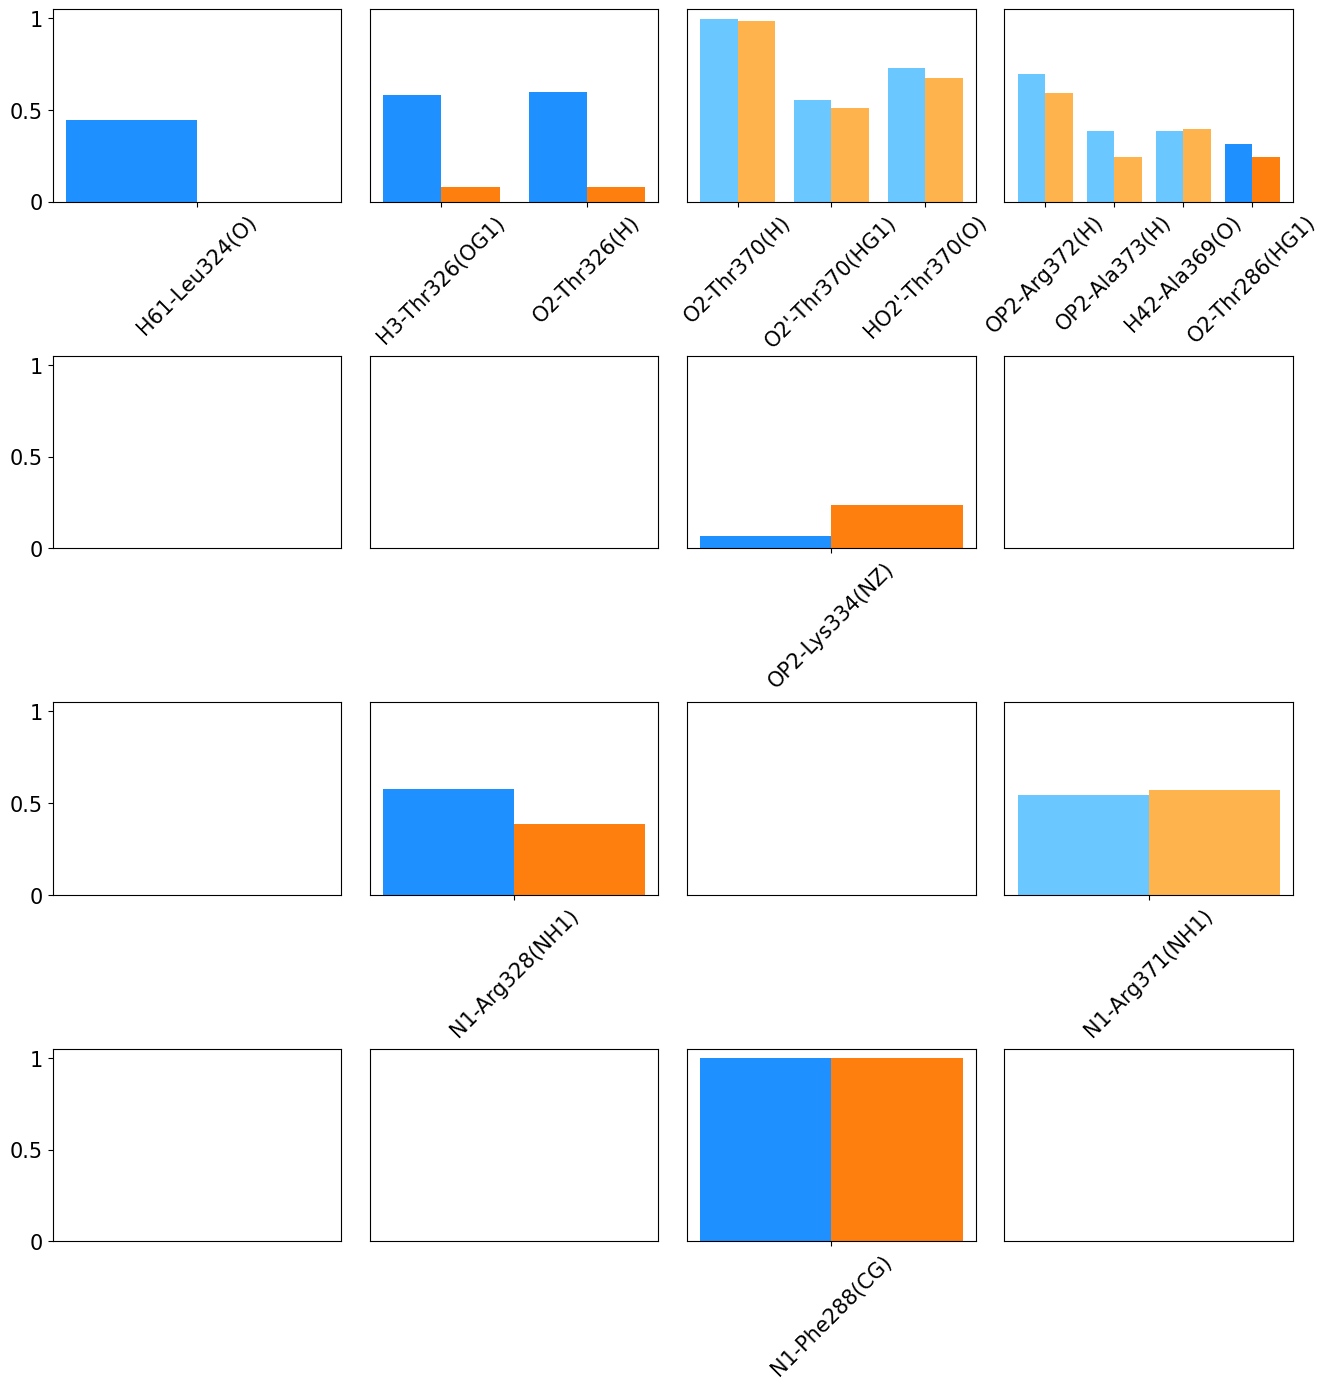

In [7]:
def make_label_protein(atom):
    # return f"{atom.residue.name}{atom.residue.index}-{atom.name}"
    resname_3 = atom.residue.name[0].upper() + atom.residue.name[1:].lower()
    return f"{resname_3}{atom.residue.index+252}({atom.name})"

def make_label_rna(atom):
    return f"{atom.name}"


atom_indices_protein_rgion = {
    "rrm": list(gleap_target.topology.select("resid  24 to 116")),
    "rgg": list(gleap_target.topology.select("resid 117 to 125")),
}

colors = [
    {
        "rrm": "#1E90FF",
        "rgg": "#6BC7FF",
    },
    {
        "rrm": "tab:orange",
        "rgg": "#FFB34D",
    },
]

FRACTION_THRESHOLDS = {
    "hbond": 0.3,
    "charge-attraction": 0.2,
    "pi-stacking": 0.3,
    "cation-pi": 0.3,
    "vdw": 0.5,
}

fig, ax = plt.subplots(4, 4)
fig.set_size_inches(16, 16)
fig.subplots_adjust(hspace=0.8)
fig.subplots_adjust(wspace=0.1)

metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_all/metastabled_trajs_concat_2.pickle", "rb"))[::50]

for i_key, (key, _cmd_interactions) in enumerate(cmd_interactions.items()):
    cmd_interactions_transpose_concat = np.concatenate(_cmd_interactions[:, :, :, ::5].transpose(0, 3, 1, 2))
    for residue_index_rna in range(11, 15):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
        atom_index_rna_residue_min = min(atom_idices_rna_residue)
        atom_index_rna_residue_max = max(atom_idices_rna_residue)
    
        i_bar = 0
        xticks = []
        for atom_index_rna_residue in range(atom_index_rna_residue_min, atom_index_rna_residue_max+1):
            for atom_index_protein in atom_indices_protein:
                fraction_0 = cmd_interactions_transpose_concat[metastabled_trajs_concat==0, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()
                fraction_1 = cmd_interactions_transpose_concat[metastabled_trajs_concat==1, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()
    
                region = "rrm"
                if atom_index_protein in atom_indices_protein_rgion["rgg"]:
                    region = "rgg"
                if fraction_0 > FRACTION_THRESHOLDS[key] or fraction_1 > FRACTION_THRESHOLDS[key]:
                    ax[i_key, residue_index_rna-11].bar(i_bar-0.2, fraction_0, width=0.4, color=colors[0][region])
                    ax[i_key, residue_index_rna-11].bar(i_bar+0.2, fraction_1, width=0.4, color=colors[1][region])
                    i_bar += 1
                    xticks.append(f"{make_label_rna(gleap_target.topology.atom(atom_index_rna_residue))}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}")
                    print(key, f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}", fraction_0, fraction_1)

        ax[i_key, residue_index_rna-11].set_ylim(0, 1.05)
        ax[i_key, residue_index_rna-11].set_xticks(range(len(xticks)), xticks, rotation=45)
    print()

for row in range(4):
    for column in range(4):
        if column == 0:
            ax[row, column].set_yticks([0, 0.5, 1], [0, 0.5, 1])
            ax[row, column].tick_params(axis='y', labelsize=15)
        else:
            ax[row, column].set_yticks([], [])
        ax[row, column].tick_params(axis='x', labelsize=15)

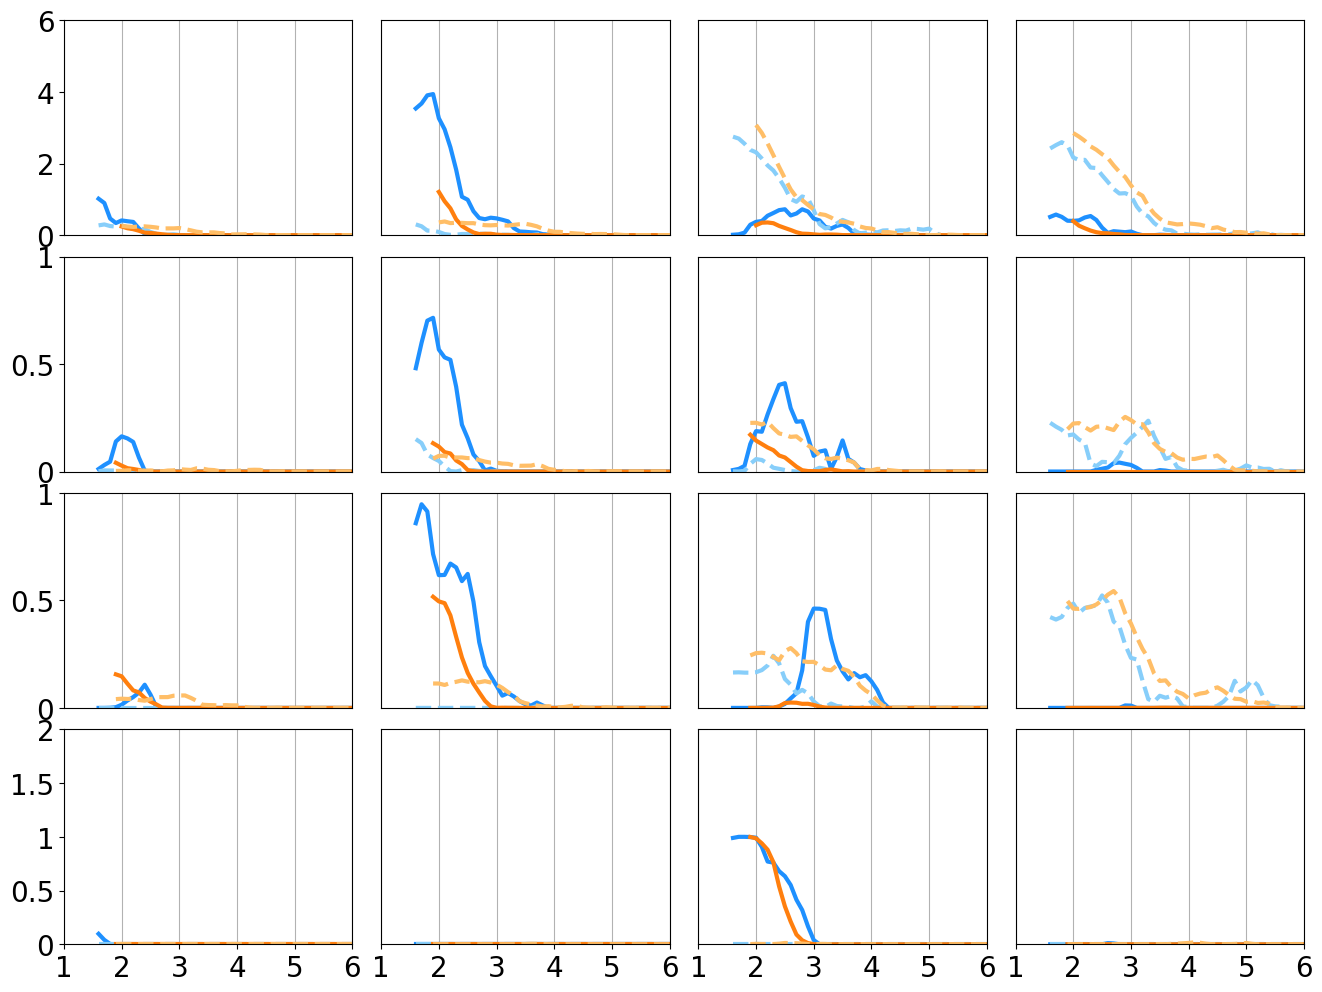

In [9]:
trial_groups_initial = [
    [4, 7, 25, 26, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]

colors = [
    {
        "rrm": "#1E90FF",
        "rgg": "lightskyblue",
    },
    {
        "rrm": "tab:orange",
        "rgg": "#FFBE67",
    },
]

y_height = {
    "hbond": 5,
    "charge-attraction": 1,
    "pi-stacking": 2,
    "cation-pi": 1,
    "vdw": 2,
}

y_ticks = {
    "hbond": [0, 2, 4, 6],
    "charge-attraction": [0, 0.5, 1],
    "pi-stacking": [0, 0.5, 1, 1.5, 2],
    "cation-pi": [0, 0.5, 1],
    "vdw": [0, 0.5, 1, 1.5, 2],
}

fig, ax = plt.subplots(4, 4)
fig.set_size_inches(16, 12)
fig.subplots_adjust(hspace=0.1)
fig.subplots_adjust(wspace=0.1)

for i_key, (key, _pacs_interactions) in enumerate(pacs_interactions.items()):
    for i_trial_group, trial_group_trials in enumerate(trial_groups_initial):
        pacs_interactions_trial_sum = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
        for trial in trial_group_trials:
            pacs_interactions_trial_sum += _pacs_interactions[trial]
        pacs_interactions_trial_mean = pacs_interactions_trial_sum / len(trial_group_trials)
        
        for residue_index_rna in range(11, 15):
            atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
        
            pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)
        
            ax[i_key, residue_index_rna-11].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rrm"], linestyle="-", linewidth=3)
            ax[i_key, residue_index_rna-11].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rgg"], linestyle="--", linewidth=3)

            ax[i_key, residue_index_rna-11].set_xlim(10, 60)
            ax[i_key, residue_index_rna-11].set_ylim(0, y_height[key])

for i_key, (key, _pacs_interactions) in enumerate(pacs_interactions.items()):
    row = i_key
    for column in range(4):
        if column == 0:
            ax[row, column].set_yticks(y_ticks[key], y_ticks[key])
            ax[row, column].tick_params(axis='y', labelsize=20)
        else:
            ax[row, column].set_yticks([], [])

        ax[row, column].set_xticks(range(10, 70, 10))
        if row == 3:
            ax[row, column].set_xticklabels(range(1, 7))
            ax[row, column].tick_params(axis='x', labelsize=20)
        else:
            ax[row, column].tick_params(axis='x', labelbottom=False, length=0)

        ax[row, column].grid(True, axis='x', color="black", alpha=0.3)